# Predictive Maintenance System — AI4I 2020

# Cleaning + EDA + Preprocessing

In [ ]:
# [1] Imports & Settings
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = "ai4i2020_predictive_maintenance.csv"   # غيّر المسار لو لازم
OUT_DIR = "outputs"                                  # فولدر الرسومات والداتا النهائية
os.makedirs(f"{OUT_DIR}/plots", exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.2
DROP_INCONSISTENT_ROWS = False   # True = يمسح الصفوف اللي الـ labels بتاعتها متضاربة (شوف الخطوة 3)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/plots/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()
    plt.close()

In [ ]:
# [2] Load Data
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print(df.head())

In [ ]:
# [3] First Look (Structure / Types / Nulls / Duplicates)
print("\n--- Info ---")
df.info()

print("\n--- Missing values ---")
print(df.isna().sum())

print("\n--- Duplicated rows ---")
print("Full-row duplicates      :", df.duplicated().sum())
print("Duplicated Product ID    :", df["Product ID"].duplicated().sum())
print("Duplicated UDI           :", df["UDI"].duplicated().sum())

print("\n--- Statistical summary ---")
print(df.describe().T)

print("\n--- Categorical columns ---")
print(df["Type"].value_counts())

In [ ]:
# [4] Cleaning
# 3.1 تنضيف أسماء الأعمدة (شيل الأقواس والمسافات عشان الكود يبقى أسهل)
df = df.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure",
})

FAILURE_TYPES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
NUM_COLS = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]

# 3.2 شيل أي duplicates (مفيش في الداتا دي بس للاحتياط)
before = len(df)
df = df.drop_duplicates()
print(f"Dropped {before - len(df)} duplicate rows")

# 3.3 فحص تناسق الـ labels (Machine failure لازم يكون = 1 لو أي نوع عطل = 1)
sub_sum = df[FAILURE_TYPES].sum(axis=1)
inc_a = (df["machine_failure"] == 1) & (sub_sum == 0)   # عطل بدون نوع
inc_b = (df["machine_failure"] == 0) & (sub_sum > 0)    # نوع عطل بدون عطل
print("\nLabel consistency check:")
print(f"  machine_failure=1 but no failure type : {inc_a.sum()}")
print(f"  machine_failure=0 but has failure type: {inc_b.sum()}  (معظمها RNF - عطل عشوائي)")
print(f"  rows with more than one failure type  : {(sub_sum > 1).sum()}")

if DROP_INCONSISTENT_ROWS:
    df = df[~(inc_a | inc_b)].reset_index(drop=True)
    print("Inconsistent rows dropped ->", df.shape)

# 3.4 التأكد إن Type متطابق مع أول حرف من Product ID
assert (df["Product ID"].str[0] == df["Type"]).all(), "Type != first letter of Product ID"

# 3.5 التأكد من منطقية القيم (domain sanity checks)
assert (df["tool_wear"] >= 0).all() and (df["rpm"] > 0).all() and (df["torque"] > 0).all()
assert (df["process_temp"] > df["air_temp"]).all(), "process temp should be higher than air temp"
print("Sanity checks passed ✔")

# 3.6 الأعمدة اللي مش مفيدة للموديل (identifiers) -> نمسحها
df = df.drop(columns=["UDI", "Product ID"])

# 3.7 تحويل Type لـ category مرتب (L < M < H) — Low / Medium / High quality
df["Type"] = pd.Categorical(df["Type"], categories=["L", "M", "H"], ordered=True)

In [ ]:
# [5] Outlier Detection (IQR) — بنعرض بس، مش بنمسح
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr))

rows = []
for c in NUM_COLS:
    mask = iqr_outliers(df[c])
    rows.append({
        "feature": c,
        "n_outliers": int(mask.sum()),
        "pct": round(mask.mean() * 100, 2),
        "failure_rate_in_outliers": round(df.loc[mask, "machine_failure"].mean() * 100, 2) if mask.any() else np.nan,
    })
outlier_report = pd.DataFrame(rows)
print("\nOutlier report (IQR):")
print(outlier_report)
print("Failure rate overall: %.2f%%" % (df["machine_failure"].mean() * 100))
# ملاحظة: الـ outliers في torque و rpm غالباً أعطال حقيقية (PWF / OSF) فمش هنمسحها.

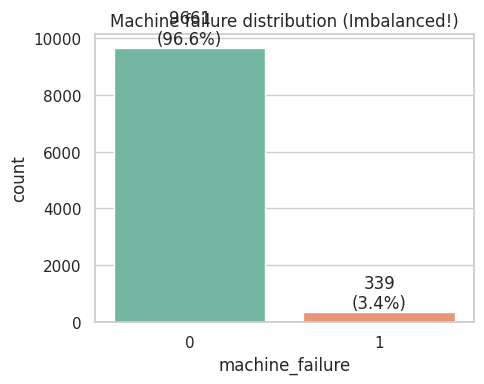

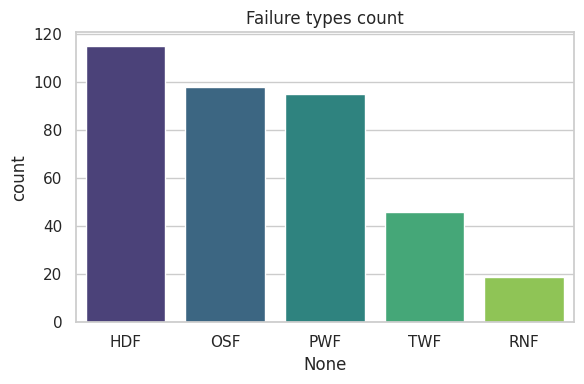

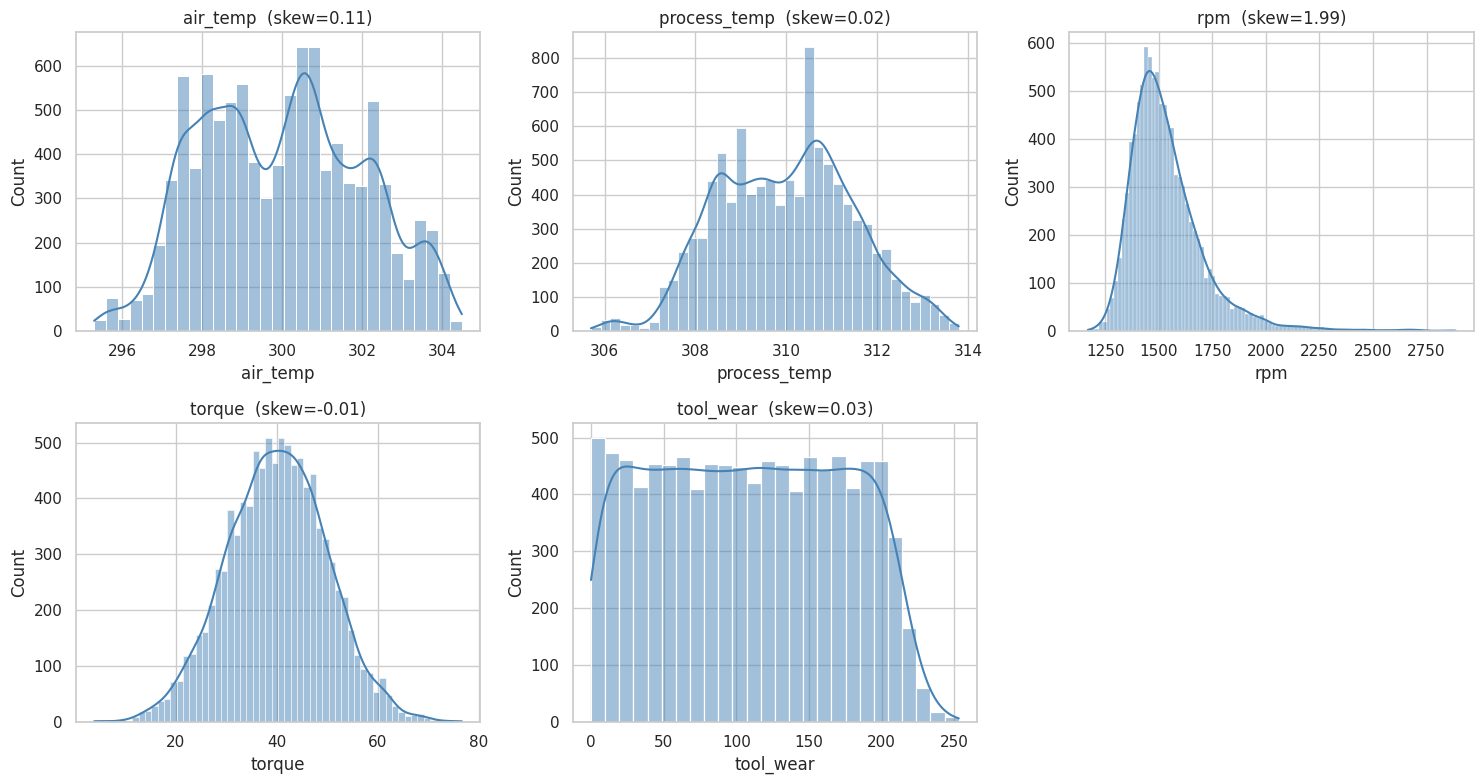

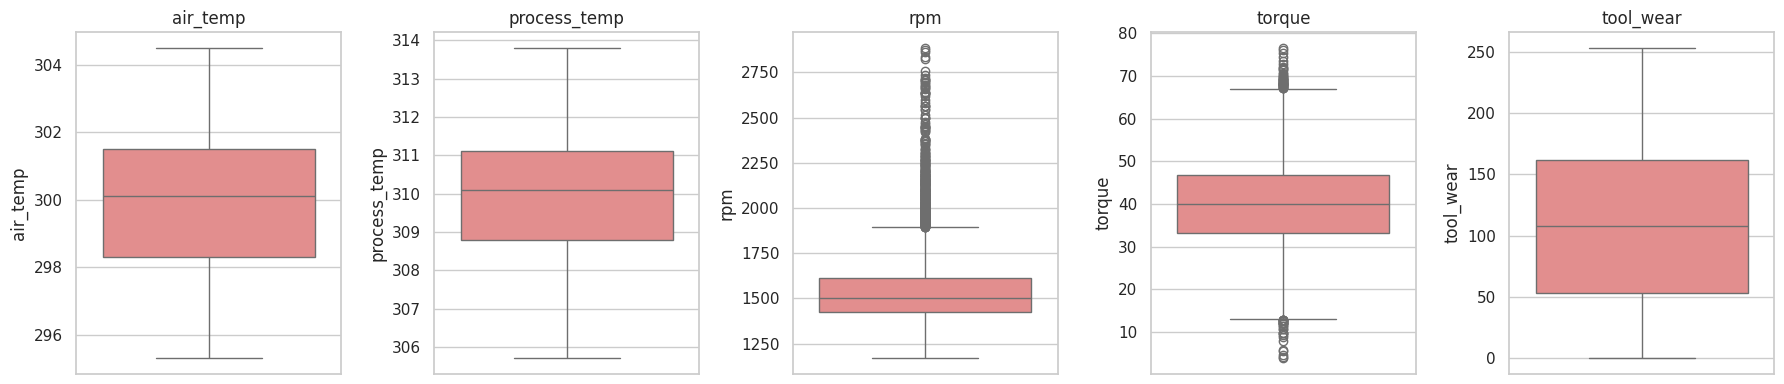

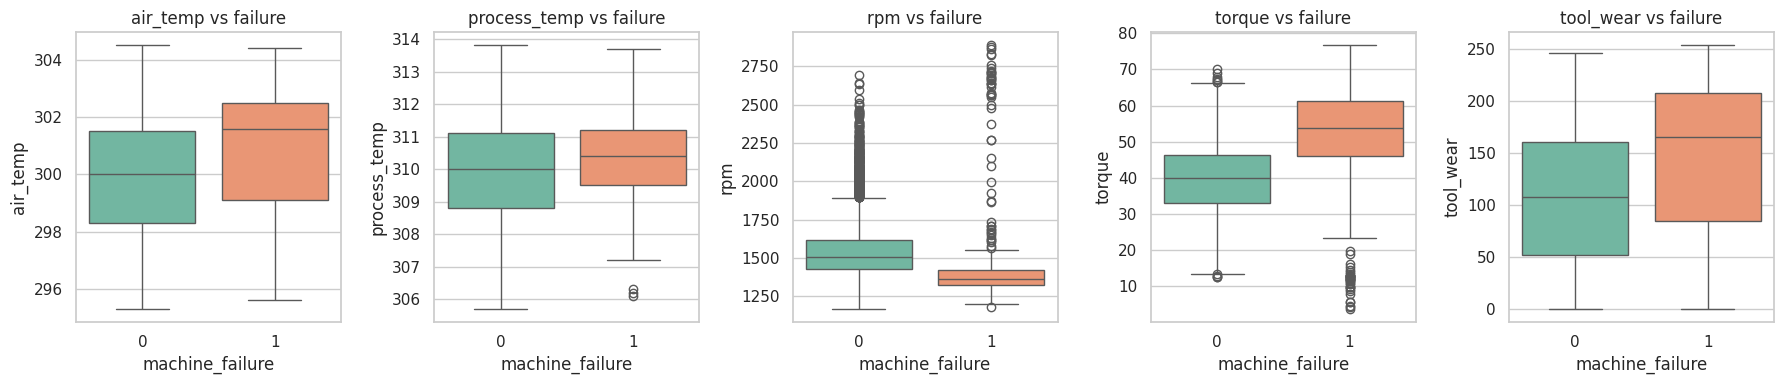

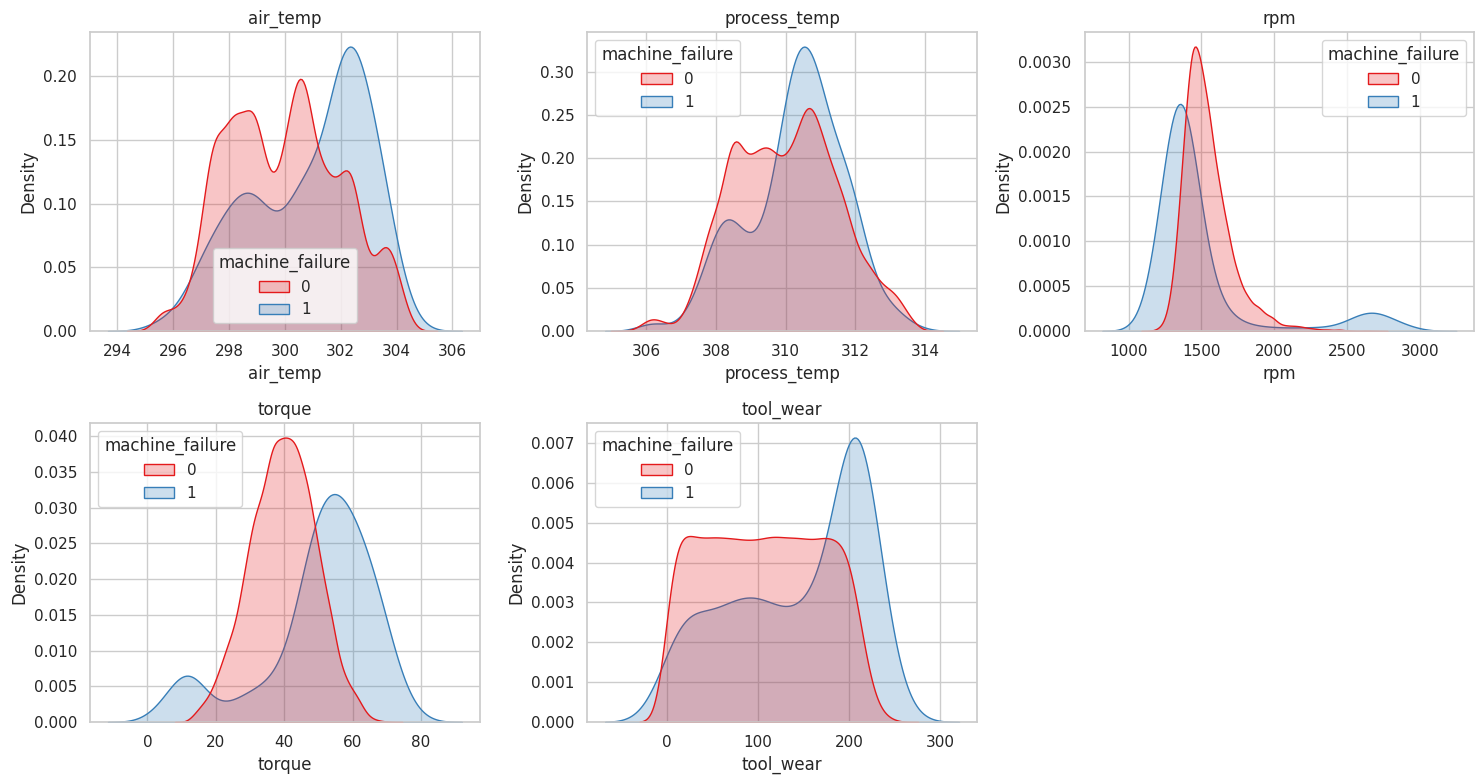


Failure rate by Type (%):
      mean  sum  count
Type                  
L     3.92  235   6000
M     2.77   83   2997
H     2.09   21   1003


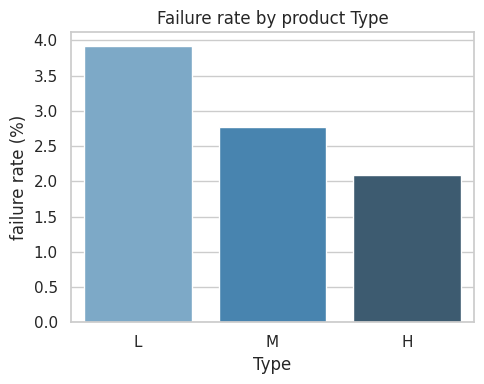

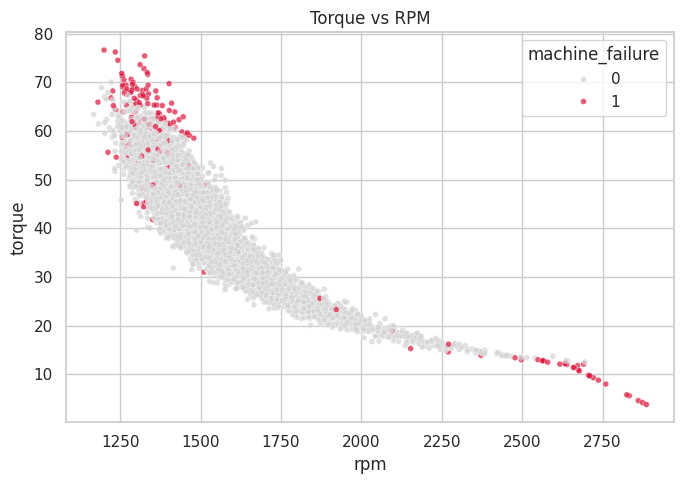

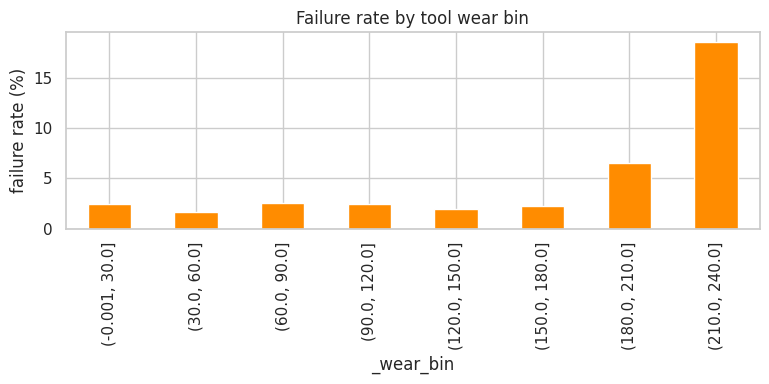

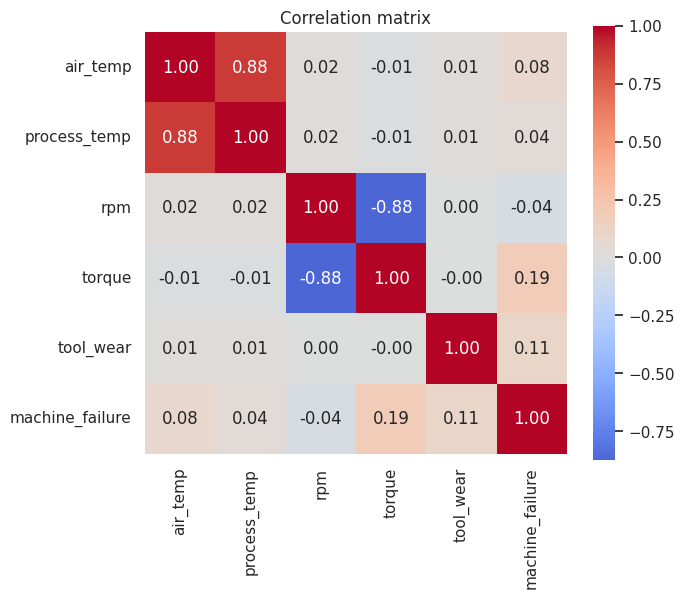


Correlation with target:
torque          0.191
tool_wear       0.105
air_temp        0.083
rpm            -0.044
process_temp    0.036
Name: machine_failure, dtype: float64


In [ ]:
# [6] EDA
# 5.1 توزيع الـ target
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="machine_failure", data=df, palette="Set2")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}\n({p.get_height()/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.title("Machine failure distribution (Imbalanced!)")
save_fig("01_target_distribution")

# 5.2 عدد كل نوع عطل
plt.figure(figsize=(6, 4))
fail_counts = df[FAILURE_TYPES].sum().sort_values(ascending=False)
sns.barplot(x=fail_counts.index, y=fail_counts.values, palette="viridis")
plt.title("Failure types count")
plt.ylabel("count")
save_fig("02_failure_types")

# 5.3 توزيع الـ numerical features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), NUM_COLS):
    sns.histplot(df[c], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{c}  (skew={df[c].skew():.2f})")
axes.ravel()[-1].axis("off")
save_fig("03_numeric_distributions")

# 5.4 Boxplots (outliers)
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, NUM_COLS):
    sns.boxplot(y=df[c], ax=ax, color="lightcoral")
    ax.set_title(c)
save_fig("04_boxplots")

# 5.5 كل feature مقابل الـ target
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, NUM_COLS):
    sns.boxplot(x="machine_failure", y=c, data=df, ax=ax, palette="Set2")
    ax.set_title(f"{c} vs failure")
save_fig("05_features_vs_target")

# 5.6 KDE مقارنة بين اللي اتعطل واللي لأ
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), NUM_COLS):
    sns.kdeplot(data=df, x=c, hue="machine_failure", common_norm=False, fill=True, ax=ax, palette="Set1")
    ax.set_title(c)
axes.ravel()[-1].axis("off")
save_fig("06_kde_by_target")

# 5.7 نسبة العطل حسب Type
type_rate = df.groupby("Type", observed=True)["machine_failure"].agg(["mean", "sum", "count"])
type_rate["mean"] *= 100
print("\nFailure rate by Type (%):")
print(type_rate.round(2))

plt.figure(figsize=(5, 4))
sns.barplot(x=type_rate.index.astype(str), y=type_rate["mean"], palette="Blues_d")
plt.ylabel("failure rate (%)")
plt.title("Failure rate by product Type")
save_fig("07_failure_by_type")

# 5.8 العلاقة بين torque و rpm (أهم علاقة في الداتا: PWF / OSF)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="rpm", y="torque", hue="machine_failure",
                palette={0: "lightgray", 1: "crimson"}, alpha=0.7, s=18)
plt.title("Torque vs RPM")
save_fig("08_torque_vs_rpm")

# 5.9 tool wear مقابل نسبة العطل
df["_wear_bin"] = pd.cut(df["tool_wear"], bins=range(0, 270, 30), include_lowest=True)
wear_rate = df.groupby("_wear_bin", observed=True)["machine_failure"].mean() * 100
plt.figure(figsize=(8, 4))
wear_rate.plot(kind="bar", color="darkorange")
plt.ylabel("failure rate (%)")
plt.title("Failure rate by tool wear bin")
save_fig("09_failure_by_tool_wear")
df = df.drop(columns="_wear_bin")

# 5.10 Correlation heatmap
corr = df[NUM_COLS + ["machine_failure"]].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix")
save_fig("10_correlation")
print("\nCorrelation with target:")
print(corr["machine_failure"].drop("machine_failure").sort_values(key=abs, ascending=False).round(3))


New features vs target correlation:
temp_diff     -0.112
power_w        0.176
wear_torque    0.190
Name: machine_failure, dtype: float64


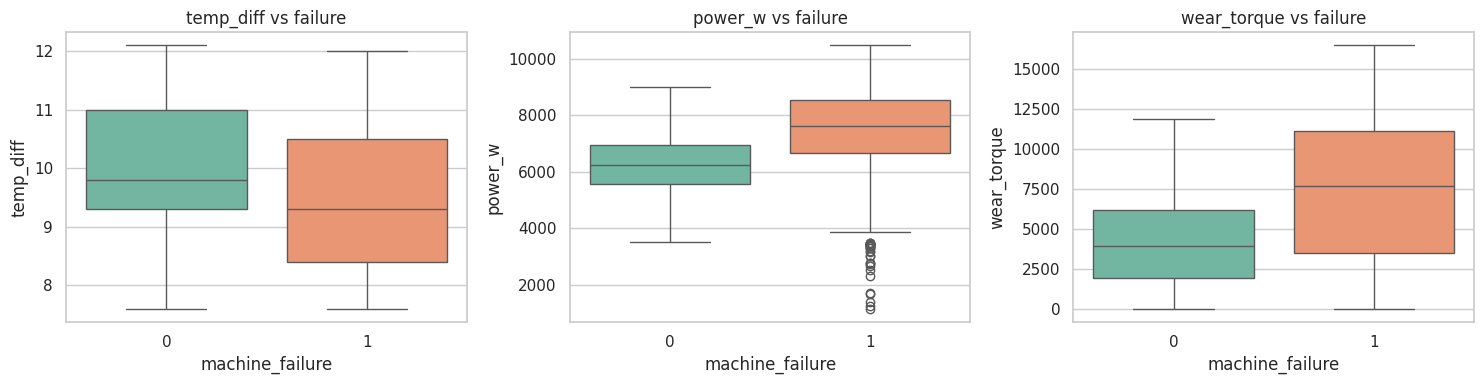

In [ ]:
# [7] Feature Engineering (مبنية على فهم الـ domain)
# الداتا دي synthetic وقواعد الأعطال معروفة:
#   HDF: فرق الحرارة صغير + rpm واطي
#   PWF: القدرة (power) خارج نطاق 3500–9000 W
#   OSF: tool_wear × torque فوق حد معين حسب الـ Type
#   TWF: tool_wear عالي (200–240 min)
df_fe = df.copy()
df_fe["temp_diff"] = df_fe["process_temp"] - df_fe["air_temp"]                     # HDF
df_fe["power_w"] = df_fe["torque"] * df_fe["rpm"] * 2 * np.pi / 60                 # PWF
df_fe["wear_torque"] = df_fe["tool_wear"] * df_fe["torque"]                        # OSF

new_feats = ["temp_diff", "power_w", "wear_torque"]
print("\nNew features vs target correlation:")
print(df_fe[new_feats + ["machine_failure"]].corr()["machine_failure"].drop("machine_failure").round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, new_feats):
    sns.boxplot(x="machine_failure", y=c, data=df_fe, ax=ax, palette="Set2")
    ax.set_title(f"{c} vs failure")
save_fig("11_engineered_features")

In [ ]:
# [8] Define X / y  +  Prevent Data Leakage
# ⚠️ أعمدة TWF/HDF/PWF/OSF/RNF هي نتيجة العطل نفسه -> لو دخلت الموديل يبقى Data Leakage.
# لو عايز تتوقع نوع العطل (multi-label) خليهم target، لكن مش features.
TARGET = "machine_failure"
LEAKAGE_COLS = FAILURE_TYPES

y = df_fe[TARGET]
X = df_fe.drop(columns=[TARGET] + LEAKAGE_COLS)
print("\nFeatures used:", list(X.columns))


Features used: ['Type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'temp_diff', 'power_w', 'wear_torque']


In [ ]:
# [9] Train / Test Split (Stratified عشان الداتا imbalanced)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}  | failure rate: {y_train.mean()*100:.2f}%")
print(f"Test : {X_test.shape}  | failure rate: {y_test.mean()*100:.2f}%")

Train: (8000, 9)  | failure rate: 3.39%
Test : (2000, 9)  | failure rate: 3.40%


In [ ]:
# [10] Encoding + Scaling (fit على الـ train بس — ده بيمنع leakage)
num_features = NUM_COLS + new_feats
cat_features = ["Type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(categories=[["L", "M", "H"]], drop="first", sparse_output=False), cat_features),
    ],
    remainder="drop",
)

X_train_arr = preprocessor.fit_transform(X_train.assign(Type=X_train["Type"].astype(str)))
X_test_arr = preprocessor.transform(X_test.assign(Type=X_test["Type"].astype(str)))

feature_names = list(preprocessor.get_feature_names_out())
X_train_proc = pd.DataFrame(X_train_arr, columns=feature_names, index=X_train.index)
X_test_proc = pd.DataFrame(X_test_arr, columns=feature_names, index=X_test.index)
print("\nProcessed features:", feature_names)
print(X_train_proc.describe().T[["mean", "std"]].round(3))


Processed features: ['num__air_temp', 'num__process_temp', 'num__rpm', 'num__torque', 'num__tool_wear', 'num__temp_diff', 'num__power_w', 'num__wear_torque', 'cat__Type_M', 'cat__Type_H']
                    mean    std
num__air_temp      0.000  1.000
num__process_temp  0.000  1.000
num__rpm           0.000  1.000
num__torque       -0.000  1.000
num__tool_wear    -0.000  1.000
num__temp_diff    -0.000  1.000
num__power_w       0.000  1.000
num__wear_torque  -0.000  1.000
cat__Type_M        0.298  0.457
cat__Type_H        0.099  0.298


In [ ]:
# [11] Class Imbalance Handling
classes = np.unique(y_train)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))
print("\nClass weights (استخدمها في class_weight= ):", class_weight_dict)
print("scale_pos_weight (لـ XGBoost/LightGBM):", round((y_train == 0).sum() / (y_train == 1).sum(), 2))

# لو عايز SMOTE (لازم تطبّقه على الـ train بس، وبعد الـ split):
#   pip install imbalanced-learn
#   from imblearn.over_sampling import SMOTE
#   X_train_res, y_train_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_proc, y_train)
#
# ملاحظة مهمة: مع الداتا دي استخدم metrics زي Recall / F1 / PR-AUC
# ومتعتمدش على Accuracy (الموديل اللي بيقول "مفيش عطل" دايماً هياخد ~96.6%).


Class weights  class_weight= ): {np.int64(0): np.float64(0.51753137533963), np.int64(1): np.float64(14.760147601476016)}
scale_pos_weight  XGBoost/LightGBM): 28.52


In [ ]:
# [12] Save Outputs
X_train_proc.assign(machine_failure=y_train.values).to_csv(f"{OUT_DIR}/train_processed.csv", index=False)
X_test_proc.assign(machine_failure=y_test.values).to_csv(f"{OUT_DIR}/test_processed.csv", index=False)
df_fe.to_csv(f"{OUT_DIR}/cleaned_with_features.csv", index=False)

try:
    import joblib
    joblib.dump(preprocessor, f"{OUT_DIR}/preprocessor.joblib")
except ImportError:
    pass

print(f"\nDone ✔  الملفات والرسومات اتحفظت في: {OUT_DIR}/")


Done ✔  الملفات والرسومات اتحفظت في: outputs/


---
# Models


In [ ]:
# [13] Imports (Training)
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_curve,
                             average_precision_score, roc_auc_score, f1_score, recall_score,
                             precision_score, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RS = RANDOM_STATE

In [ ]:
!pip install xgboost lightgbm

In [ ]:
# [14] Load processed data
# بنستخدم الداتا الجاهزة من الجزء الأول مباشرة (من غير ما نقرأ الملفات تاني)
X_train, X_test = X_train_proc.copy(), X_test_proc.copy()   # y_train / y_test موجودين من الـ split
print("Train:", X_train.shape, "| Test:", X_test.shape)

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos

Train: (8000, 10) | Test: (2000, 10)


In [ ]:
# [15] Models
# كلهم بيتعاملوا مع الـ imbalance عن طريق class_weight (من غير SMOTE)
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RS),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=6, min_samples_leaf=5, random_state=RS),
    "SVM (RBF)": SVC(class_weight="balanced", probability=True, random_state=RS),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                            min_samples_leaf=2, n_jobs=-1, random_state=RS),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, class_weight="balanced_subsample",
                                        min_samples_leaf=2, n_jobs=-1, random_state=RS),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", learning_rate=0.08,
                                                           max_iter=300, random_state=RS),
}
# XGBoost / LightGBM اختياريين (لو متسطبين)
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.08, subsample=0.9,
                                      colsample_bytree=0.9, scale_pos_weight=spw, eval_metric="aucpr",
                                      random_state=RS, n_jobs=-1)
except ImportError:
    print("xgboost not installed -> skipped (pip install xgboost)")
try:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                                        class_weight="balanced", random_state=RS, verbose=-1)
except ImportError:
    print("lightgbm not installed -> skipped (pip install lightgbm)")

In [ ]:
# [16] Cross-validation على الـ train (Stratified 5-fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
scoring = {"precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{k: res[f"test_{k}"].mean() for k in scoring},
                 "f1_std": res["test_f1"].std()})
    print(f"{name:22s} F1={rows[-1]['f1']:.3f}  Recall={rows[-1]['recall']:.3f}  PR-AUC={rows[-1]['pr_auc']:.3f}")

cv_df = pd.DataFrame(rows).sort_values("pr_auc", ascending=False).round(4).reset_index(drop=True)
print("\nCross-validation results (sorted by PR-AUC):")
print(cv_df.to_string(index=False))
cv_df.to_csv(f"{OUT_DIR}/cv_results.csv", index=False)

Logistic Regression    F1=0.271  Recall=0.841  PR-AUC=0.459
Decision Tree          F1=0.569  Recall=0.919  PR-AUC=0.836
SVM (RBF)              F1=0.464  Recall=0.882  PR-AUC=0.688
Random Forest          F1=0.862  Recall=0.797  PR-AUC=0.889
Extra Trees            F1=0.782  Recall=0.760  PR-AUC=0.833
HistGradientBoosting   F1=0.862  Recall=0.819  PR-AUC=0.867
XGBoost                F1=0.806  Recall=0.823  PR-AUC=0.850
LightGBM               F1=0.831  Recall=0.830  PR-AUC=0.856

Cross-validation results (sorted by PR-AUC):
               model  precision  recall     f1  roc_auc  pr_auc  f1_std
       Random Forest     0.9384  0.7970 0.8616   0.9789  0.8888  0.0389
HistGradientBoosting     0.9098  0.8191 0.8620   0.9681  0.8673  0.0301
            LightGBM     0.8348  0.8300 0.8314   0.9771  0.8562  0.0189
             XGBoost     0.7911  0.8228 0.8059   0.9765  0.8498  0.0203
       Decision Tree     0.4128  0.9189 0.5694   0.9457  0.8362  0.0115
         Extra Trees     0.8054  0.7602 0.

In [ ]:
# [17] اختيار أفضل موديل + ضبط الـ threshold (من out-of-fold predictions — مش من الـ test)
best_name = cv_df.loc[0, "model"]
best_model = models[best_name]
print("\nBest model by PR-AUC:", best_name)

oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = float(thr[np.argmax(f1s)])
print(f"Best threshold (max F1 on OOF): {best_thr:.3f}")


Best model by PR-AUC: Random Forest
Best threshold (max F1 on OOF): 0.471


In [ ]:
# [18] Final fit + تقييم على الـ test
best_model.fit(X_train, y_train)
proba = best_model.predict_proba(X_test)[:, 1]

def evaluate(proba, thr):
    pred = (proba >= thr).astype(int)
    return {"threshold": round(thr, 3),
            "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba),
            "pr_auc": average_precision_score(y_test, proba)}

summary = pd.DataFrame([evaluate(proba, 0.5), evaluate(proba, best_thr)],
                       index=["default thr=0.5", "tuned threshold"]).round(4)
print("\nTest-set results:")
print(summary)
summary.to_csv(f"{OUT_DIR}/test_results.csv")

pred = (proba >= best_thr).astype(int)
print("\nClassification report (tuned threshold):")
print(classification_report(y_test, pred, target_names=["No failure", "Failure"], digits=3))


Test-set results:
                 threshold  precision  recall      f1  roc_auc  pr_auc
default thr=0.5      0.500     0.9492  0.8235  0.8819   0.9714  0.8687
tuned threshold      0.471     0.9492  0.8235  0.8819   0.9714  0.8687

Classification report (tuned threshold):
              precision    recall  f1-score   support

  No failure      0.994     0.998     0.996      1932
     Failure      0.949     0.824     0.882        68

    accuracy                          0.993      2000
   macro avg      0.971     0.911     0.939      2000
weighted avg      0.992     0.993     0.992      2000



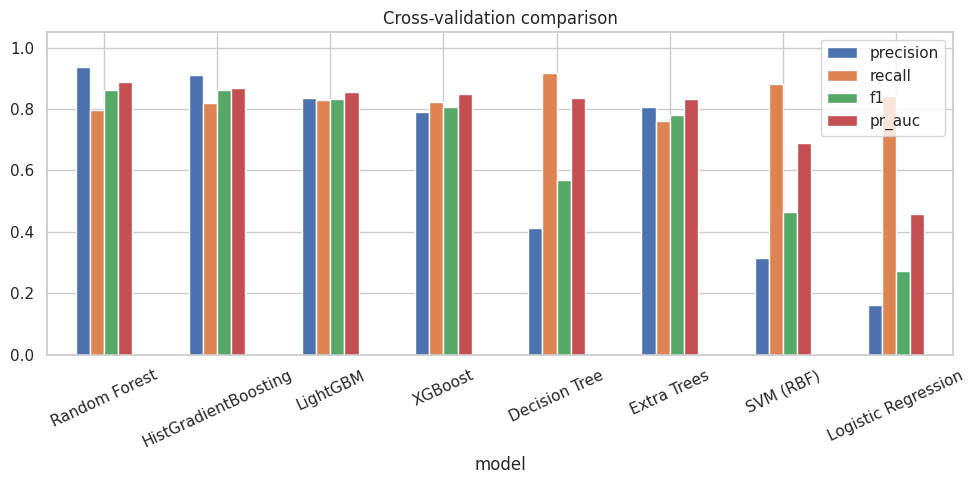

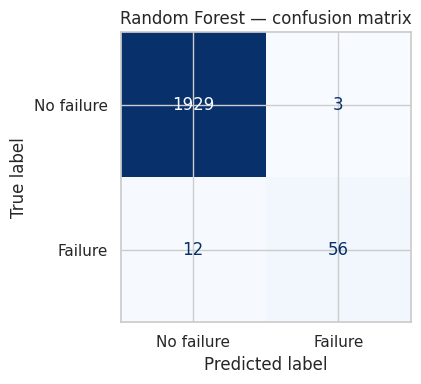

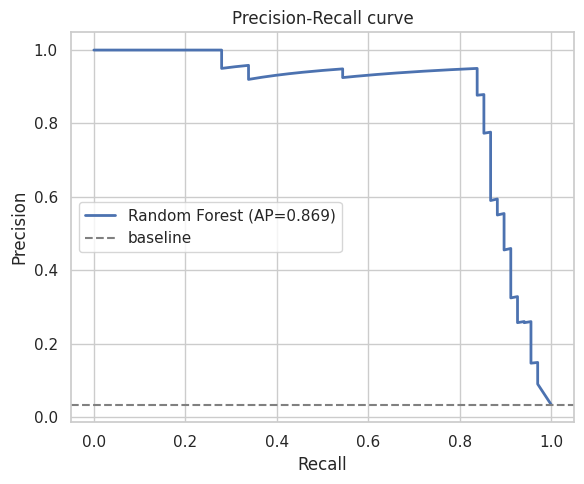

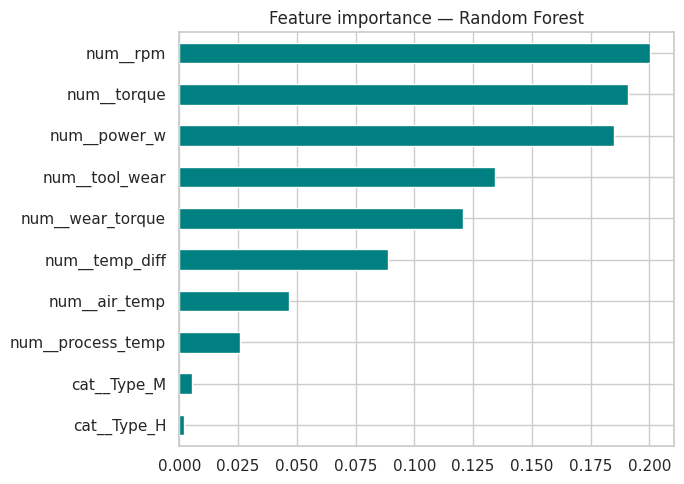


Top features:
 num__rpm            0.2005
num__torque         0.1911
num__power_w        0.1850
num__tool_wear      0.1342
num__wear_torque    0.1208
dtype: float64


In [ ]:
# [19] Plots
# 6.1 مقارنة الموديلات
ax = cv_df.set_index("model")[["precision", "recall", "f1", "pr_auc"]].plot(kind="bar", figsize=(10, 5), rot=25)
ax.set_title("Cross-validation comparison"); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/plots/12_model_comparison.png", dpi=130); plt.show()

# 6.2 Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No failure", "Failure"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{best_name} — confusion matrix")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/plots/13_confusion_matrix.png", dpi=130); plt.show()

# 6.3 Precision-Recall curve
p, r, _ = precision_recall_curve(y_test, proba)
plt.figure(figsize=(6, 5))
plt.plot(r, p, lw=2, label=f"{best_name} (AP={average_precision_score(y_test, proba):.3f})")
plt.axhline(y_test.mean(), ls="--", color="gray", label="baseline")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall curve"); plt.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/plots/14_pr_curve.png", dpi=130); plt.show()

# 6.4 Feature importance (لو الموديل بيدعمها، وإلا permutation importance)
if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=X_train.columns)
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                                n_repeats=10, random_state=RS, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=X_train.columns)
imp = imp.sort_values()
plt.figure(figsize=(7, 5)); imp.plot(kind="barh", color="teal")
plt.title(f"Feature importance — {best_name}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/plots/15_feature_importance.png", dpi=130); plt.show()
print("\nTop features:\n", imp.sort_values(ascending=False).head(5).round(4))

In [ ]:
# [20] Save model
joblib.dump({"model": best_model, "threshold": best_thr, "features": list(X_train.columns)},
            f"{OUT_DIR}/best_model.joblib")
print(f"\nDone ✔  best_model.joblib اتحفظ في {OUT_DIR}/")


Done ✔  best_model.jobliboutputs/


## استخدام الموديل على داتا جديدة
```python
import joblib, pandas as pd
prep = joblib.load("outputs/preprocessor.joblib")
bundle = joblib.load("outputs/best_model.joblib")
# new_df لازم يحتوي: Type, air_temp, process_temp, rpm, torque, tool_wear
# + temp_diff, power_w, wear_torque (نفس معادلات الـ feature engineering)
X_new = prep.transform(new_df)
proba = bundle["model"].predict_proba(X_new)[:, 1]
alert = proba >= bundle["threshold"]
```